# Handwritten Character Recognition using CNN

**AgenticX Machine Learning Internship — Project 1**

## Objective
Classify handwritten digits using a Convolutional Neural Network (CNN).

## Dataset
MNIST

## Experiments
1. Non-neural baseline
2. Simple CNN
3. CNN architectural experiments
4. Error analysis
5. Inference-time measurement

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Project paths

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")
PREDICTIONS_DIR = os.path.join(PROJECT_DIR, "predictions")

print("Project initialized successfully.")

Project initialized successfully.


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition"

print("Project directory exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nContents of project directory:")
    print(os.listdir(PROJECT_DIR))

Project directory exists: True

Contents of project directory:
['data', 'checkpoints', 'models', 'results', 'plots', 'predictions']


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)

print("\nAvailable GPUs:")
print(tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: True

Available GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
progress_file = os.path.join(PROJECT_DIR, "progress.txt")

with open(progress_file, "w") as f:
    f.write("Step 1 completed: Project setup and Google Drive connection.\n")

print("Progress checkpoint saved.")

Progress checkpoint saved.


# Step 2 — Load MNIST Dataset

MNIST contains 70,000 grayscale handwritten digit images:
- 60,000 training images
- 10,000 test images
- Image size: 28 × 28 pixels
- Classes: digits 0–9

In [ ]:
import os
import tensorflow as tf
from tensorflow import keras

DATA_DIR = os.path.join(PROJECT_DIR, "data")

print("TensorFlow version:", tf.__version__)
print("Data directory:", DATA_DIR)

TensorFlow version: 2.20.0
Data directory: /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/data


In [ ]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Dataset loaded successfully!")
print()
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [ ]:
dataset_path = os.path.join(DATA_DIR, "mnist_dataset.npz")

import numpy as np

np.savez_compressed(
    dataset_path,
    x_train=x_train,
    y_train=y_train,
    x_test=x_test,
    y_test=y_test
)

print("Dataset checkpoint saved to:")
print(dataset_path)

Dataset checkpoint saved to:
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/data/mnist_dataset.npz


# Step 3 — Exploratory Data Analysis

Before training the models, we inspect the MNIST dataset to understand:

- Image dimensions
- Pixel value range
- Number of classes
- Class distribution
- Example handwritten digits

In [ ]:
# Step 3.1 — Basic Dataset Information

print("===== MNIST DATASET INFORMATION =====")

print("\nTraining data:")
print("Images shape :", x_train.shape)
print("Labels shape :", y_train.shape)

print("\nTest data:")
print("Images shape :", x_test.shape)
print("Labels shape :", y_test.shape)

print("\nNumber of training images:", len(x_train))
print("Number of test images:", len(x_test))

print("\nImage dimensions:", x_train.shape[1], "x", x_train.shape[2])

print("\nNumber of classes:", len(np.unique(y_train)))
print("Classes:", np.unique(y_train))

print("\nPixel data type:", x_train.dtype)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

===== MNIST DATASET INFORMATION =====

Training data:
Images shape : (60000, 28, 28)
Labels shape : (60000,)

Test data:
Images shape : (10000, 28, 28)
Labels shape : (10000,)

Number of training images: 60000
Number of test images: 10000

Image dimensions: 28 x 28

Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]

Pixel data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


## Step 3.2 — Visualize Sample Images

Display a selection of handwritten digits from the MNIST training dataset.

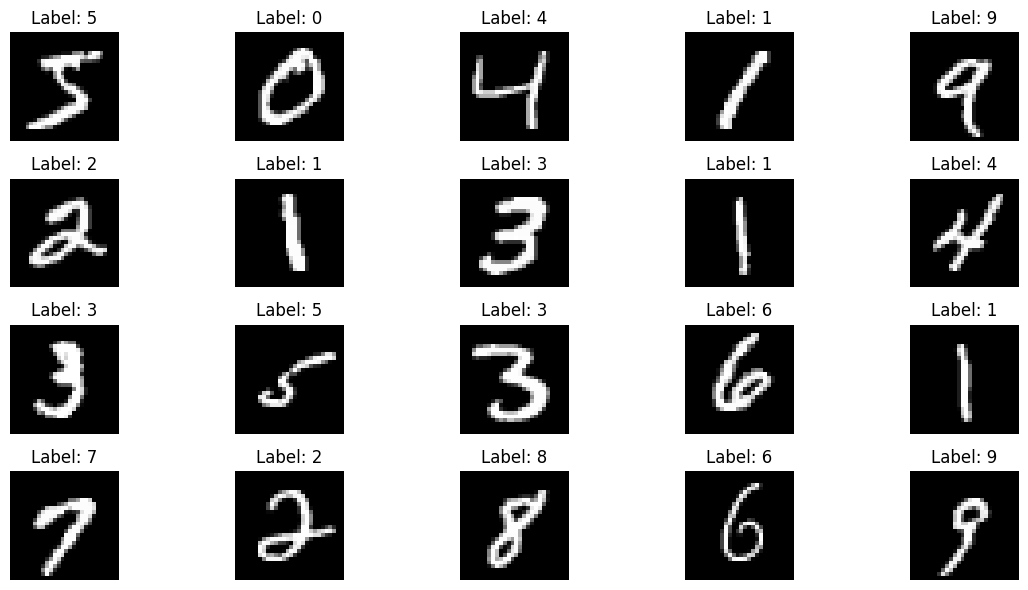

In [ ]:
# Step 3.2 — Visualize sample handwritten digits

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 3.3 — Class Distribution

Analyze the number of training and test samples available for each digit class.

In [ ]:
# Step 3.3 — Analyze class distribution

import numpy as np
import matplotlib.pyplot as plt

# Count training samples for each class
train_counts = np.bincount(y_train, minlength=10)

# Count test samples for each class
test_counts = np.bincount(y_test, minlength=10)

print("===== TRAINING SET =====")
for digit, count in enumerate(train_counts):
    print(f"Digit {digit}: {count} images")

print("\n===== TEST SET =====")
for digit, count in enumerate(test_counts):
    print(f"Digit {digit}: {count} images")

===== TRAINING SET =====
Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images

===== TEST SET =====
Digit 0: 980 images
Digit 1: 1135 images
Digit 2: 1032 images
Digit 3: 1010 images
Digit 4: 982 images
Digit 5: 892 images
Digit 6: 958 images
Digit 7: 1028 images
Digit 8: 974 images
Digit 9: 1009 images


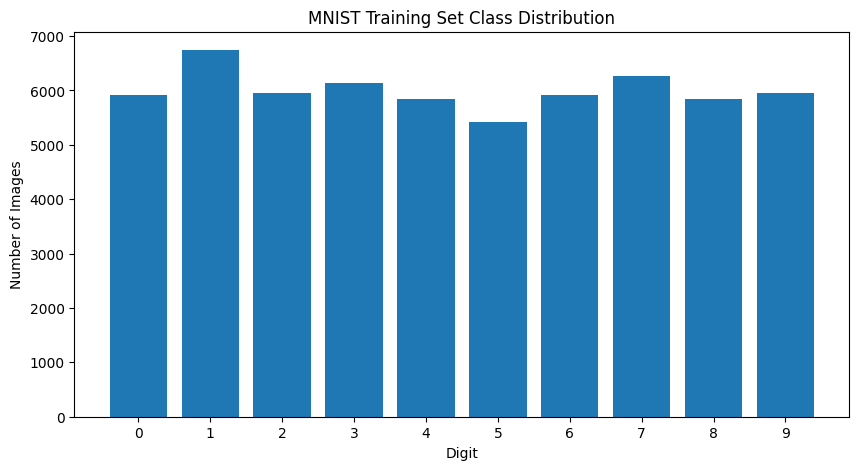

In [ ]:
# Plot class distribution

digits = np.arange(10)

plt.figure(figsize=(10, 5))
plt.bar(digits, train_counts)

plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("MNIST Training Set Class Distribution")
plt.xticks(digits)

plt.show()

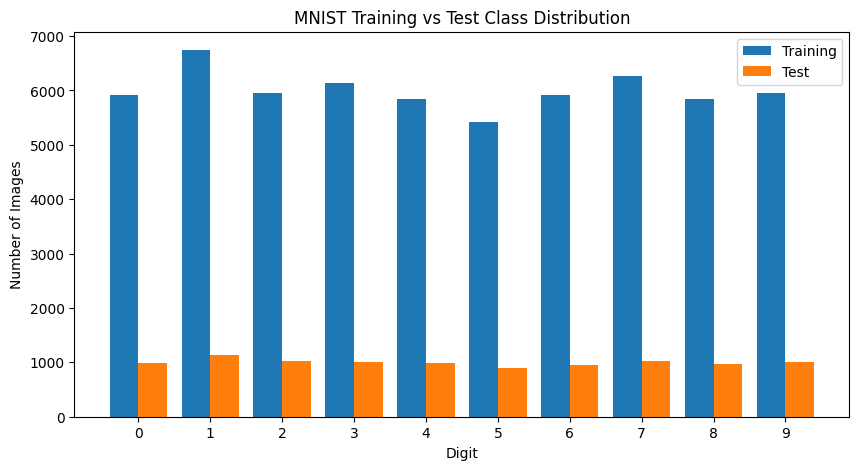

In [ ]:
# Plot training vs test class distribution

x = np.arange(10)
width = 0.4

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, train_counts, width, label="Training")
plt.bar(x + width/2, test_counts, width, label="Test")

plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.title("MNIST Training vs Test Class Distribution")
plt.xticks(x)
plt.legend()

plt.show()

## Step 4.1 — Normalize Pixel Values

The original MNIST images contain pixel values from 0 to 255.

For neural-network training, we normalize these values to the range 0 to 1.

In [ ]:
# Step 4.1 — Normalize pixel values

x_train_normalized = x_train.astype("float32") / 255.0
x_test_normalized = x_test.astype("float32") / 255.0

print("Original pixel range:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

print("\nNormalized pixel range:")
print("Minimum:", x_train_normalized.min())
print("Maximum:", x_train_normalized.max())

Original pixel range:
Minimum: 0
Maximum: 255

Normalized pixel range:
Minimum: 0.0
Maximum: 1.0


In [ ]:
# Step 4.2 — Add channel dimension for CNN

x_train_cnn = np.expand_dims(x_train_normalized, axis=-1)
x_test_cnn = np.expand_dims(x_test_normalized, axis=-1)

print("CNN training shape:", x_train_cnn.shape)
print("CNN test shape:", x_test_cnn.shape)

CNN training shape: (60000, 28, 28, 1)
CNN test shape: (10000, 28, 28, 1)


## Step 4.3 — Prepare Data for Non-Neural Baseline

For Logistic Regression, each 28 × 28 image is flattened into a vector containing 784 pixel features.

In [ ]:
# Step 4.3 — Flatten images for Logistic Regression

x_train_flat = x_train_normalized.reshape(x_train_normalized.shape[0], -1)
x_test_flat = x_test_normalized.reshape(x_test_normalized.shape[0], -1)

print("Logistic Regression training shape:", x_train_flat.shape)
print("Logistic Regression test shape:", x_test_flat.shape)

Logistic Regression training shape: (60000, 784)
Logistic Regression test shape: (10000, 784)


In [ ]:
# Step 4.4 — Verify labels

print("Training labels shape:", y_train.shape)
print("Test labels shape:", y_test.shape)

print("\nFirst 10 training labels:")
print(y_train[:10])

print("\nFirst 10 test labels:")
print(y_test[:10])

Training labels shape: (60000,)
Test labels shape: (10000,)

First 10 training labels:
[5 0 4 1 9 2 1 3 1 4]

First 10 test labels:
[7 2 1 0 4 1 4 9 5 9]


In [ ]:
# Step 4.5 — Save preprocessing checkpoint

preprocessed_path = os.path.join(
    DATA_DIR,
    "mnist_preprocessed.npz"
)

np.savez_compressed(
    preprocessed_path,
    x_train_cnn=x_train_cnn,
    x_test_cnn=x_test_cnn,
    x_train_flat=x_train_flat,
    x_test_flat=x_test_flat,
    y_train=y_train,
    y_test=y_test
)

print("Preprocessing checkpoint saved to:")
print(preprocessed_path)

Preprocessing checkpoint saved to:
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/data/mnist_preprocessed.npz


In [ ]:
# Update project progress

with open(progress_file, "a") as f:
    f.write("Step 2 completed: MNIST dataset loaded and saved.\n")
    f.write("Step 3 completed: Dataset exploration and visualization completed.\n")
    f.write("Step 4 completed: Data preprocessing completed and saved.\n")

print("Project progress updated.")

Project progress updated.


# Step 5 — Non-Neural Baseline

## Logistic Regression

Before building a CNN, we establish a non-neural baseline using Logistic Regression.

The images are represented as 784-dimensional feature vectors (28 × 28 pixels).

In [ ]:
# Step 5.1 — Import libraries

import os
import time
import joblib
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Step 5.2 — Verify preprocessed data

preprocessed_path = os.path.join(
    DATA_DIR,
    "mnist_preprocessed.npz"
)

data = np.load(preprocessed_path)

x_train_flat = data["x_train_flat"]
x_test_flat = data["x_test_flat"]
y_train = data["y_train"]
y_test = data["y_test"]

print("Training data:", x_train_flat.shape)
print("Test data:", x_test_flat.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Training data: (60000, 784)
Test data: (10000, 784)
Training labels: (60000,)
Test labels: (10000,)


In [ ]:
# Step 5.3 — Train Logistic Regression baseline
# Increased max_iter to allow the model to converge properly

baseline_model = LogisticRegression(
    max_iter=300,
    solver="lbfgs"
)

print("Starting Logistic Regression training...")

start_time = time.perf_counter()

baseline_model.fit(x_train_flat, y_train)

training_time = time.perf_counter() - start_time

print("\nTraining completed.")
print(f"Training time: {training_time:.2f} seconds")
print(f"Iterations used: {baseline_model.n_iter_}")

Starting Logistic Regression training...

Training completed.
Training time: 95.70 seconds
Iterations used: [259]


In [ ]:
# Step 5.4 — Evaluate Logistic Regression baseline

from sklearn.metrics import accuracy_score

print("Starting baseline evaluation...")

start_time = time.perf_counter()

y_pred = baseline_model.predict(x_test_flat)

inference_time = time.perf_counter() - start_time

accuracy = accuracy_score(y_test, y_pred)

print("\n===== LOGISTIC REGRESSION RESULTS =====")
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Total inference time: {inference_time:.4f} seconds")
print(
    f"Average inference time per image: "
    f"{(inference_time / len(x_test_flat)) * 1000:.4f} ms"
)

Starting baseline evaluation...

===== LOGISTIC REGRESSION RESULTS =====
Test Accuracy: 0.9259
Test Accuracy: 92.59%
Total inference time: 0.1567 seconds
Average inference time per image: 0.0157 ms


In [ ]:
# Step 5.5 — Save Logistic Regression baseline model

baseline_model_path = os.path.join(
    MODEL_DIR,
    "logistic_regression_baseline.joblib"
)

joblib.dump(baseline_model, baseline_model_path)

print("Baseline model saved successfully!")
print(baseline_model_path)

Baseline model saved successfully!
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/models/logistic_regression_baseline.joblib


In [ ]:
# Step 5.6 — Save baseline metrics

baseline_results_path = os.path.join(
    RESULTS_DIR,
    "baseline_metrics.npz"
)

np.savez(
    baseline_results_path,
    accuracy=accuracy,
    training_time=training_time,
    inference_time=inference_time,
    average_inference_time_ms=(
        inference_time / len(x_test_flat)
    ) * 1000
)

print("Baseline metrics saved successfully!")
print(baseline_results_path)

Baseline metrics saved successfully!
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/baseline_metrics.npz


In [ ]:
# Step 5.7 — Classification Report

from sklearn.metrics import classification_report

print("===== CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     0.9532    0.9776    0.9652       980
           1     0.9619    0.9789    0.9703      1135
           2     0.9291    0.9012    0.9149      1032
           3     0.9056    0.9119    0.9087      1010
           4     0.9369    0.9369    0.9369       982
           5     0.8964    0.8733    0.8847       892
           6     0.9411    0.9509    0.9460       958
           7     0.9331    0.9232    0.9281      1028
           8     0.8805    0.8778    0.8792       974
           9     0.9113    0.9167    0.9140      1009

    accuracy                         0.9259     10000
   macro avg     0.9249    0.9248    0.9248     10000
weighted avg     0.9257    0.9259    0.9257     10000



In [ ]:
# Step 5.8 — Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("===== CONFUSION MATRIX =====")
print(cm)

===== CONFUSION MATRIX =====
[[ 958    0    1    3    1    9    4    3    1    0]
 [   0 1111    4    2    0    2    3    2   11    0]
 [   6    9  930   16   10    3   12    9   33    4]
 [   4    1   17  921    1   24    2   10   22    8]
 [   1    3    7    3  920    0    7    5    6   30]
 [   9    2    3   35    8  779   15    6   31    4]
 [   8    3    7    2    7   17  911    2    1    0]
 [   1    7   24    6    6    1    0  949    2   32]
 [   9   12    7   20    8   28   14    9  855   12]
 [   9    7    1    9   21    6    0   22    9  925]]


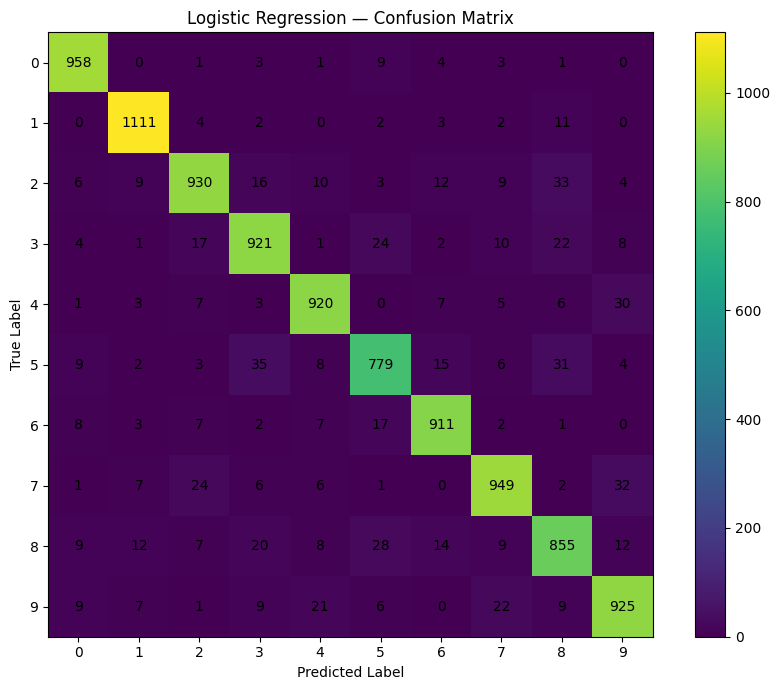

Confusion matrix plot saved to:
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/plots/logistic_regression_confusion_matrix.png


In [ ]:
# Step 5.9 — Visualize Confusion Matrix

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(range(10))
plt.yticks(range(10))

plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

confusion_matrix_path = os.path.join(
    PLOTS_DIR,
    "logistic_regression_confusion_matrix.png"
)

plt.savefig(confusion_matrix_path, dpi=150)
plt.show()

print("Confusion matrix plot saved to:")
print(confusion_matrix_path)

In [ ]:
# Step 5.10 — Update project progress

with open(progress_file, "a") as f:
    f.write(
        "Step 5 completed: Logistic Regression baseline trained, "
        "evaluated, saved, and analyzed.\n"
    )

print("Project progress updated.")

Project progress updated.


In [ ]:
# Step 6.1 — Load preprocessed MNIST data

import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

PROJECT_DIR = "/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
PLOTS_DIR = os.path.join(PROJECT_DIR, "plots")
CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
PREDICTIONS_DIR = os.path.join(PROJECT_DIR, "predictions")

progress_file = os.path.join(PROJECT_DIR, "progress.txt")

# Load preprocessing checkpoint
preprocessed_path = os.path.join(
    DATA_DIR,
    "mnist_preprocessed.npz"
)

data = np.load(preprocessed_path)

x_train_cnn = data["x_train_cnn"]
x_test_cnn = data["x_test_cnn"]
y_train = data["y_train"]
y_test = data["y_test"]

print("Data loaded successfully!")
print("Training images:", x_train_cnn.shape)
print("Test images:", x_test_cnn.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

Data loaded successfully!
Training images: (60000, 28, 28, 1)
Test images: (10000, 28, 28, 1)
Training labels: (60000,)
Test labels: (10000,)


In [ ]:
# Step 6.2 — Build CNN v1

cnn_v1 = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Convolutional layer
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    # Reduce spatial dimensions
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # 10 output classes (digits 0–9)
    layers.Dense(
        10,
        activation="softmax"
    )
])

cnn_v1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Step 6.3 — Compile CNN v1

cnn_v1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN v1 compiled successfully!")

CNN v1 compiled successfully!


In [ ]:
# Step 6.4 — Create CNN v1 checkpoint callback

checkpoint_path = os.path.join(
    CHECKPOINT_DIR,
    "cnn_v1_epoch_{epoch:02d}.weights.h5"
)

checkpoint_callback = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=True,
    save_freq="epoch",
    verbose=1
)

print("Checkpoint callback created!")
print("Checkpoints will be saved to:")
print(CHECKPOINT_DIR)

Checkpoint callback created!
Checkpoints will be saved to:
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/checkpoints


In [ ]:
# Step 6.5 — Train CNN v1

print("Starting CNN v1 training...")

history_v1 = cnn_v1.fit(
    x_train_cnn,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[checkpoint_callback],
    verbose=1
)

print("\nCNN v1 training completed!")

Starting CNN v1 training...
Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8636 - loss: 0.4674
Epoch 1: saving model to /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/checkpoints/cnn_v1_epoch_01.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/checkpoints/cnn_v1_epoch_01.weights.h5
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9305 - loss: 0.2390 - val_accuracy: 0.9795 - val_loss: 0.0785
Epoch 2/10
418/422 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9761 - loss: 0.0839
Epoch 2: saving model to /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/checkpoints/cnn_v1_epoch_02.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/checkpoints/cnn_v1_epoch_02.weights.h5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9787 - loss: 0.0737 - val_accuracy: 0.9828 - val_loss: 0.0600
Epoch 3/10
417/422 ━━━━━━━

In [ ]:
history_path = os.path.join(
    RESULTS_DIR,
    "cnn_v1_history.npz"
)

np.savez(
    history_path,
    accuracy=history_v1.history["accuracy"],
    val_accuracy=history_v1.history["val_accuracy"],
    loss=history_v1.history["loss"],
    val_loss=history_v1.history["val_loss"]
)

print("CNN v1 training history saved successfully!")
print(history_path)

CNN v1 training history saved successfully!
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/results/cnn_v1_history.npz


In [ ]:
cnn_v1_model_path = os.path.join(
    MODEL_DIR,
    "cnn_v1.keras"
)

cnn_v1.save(cnn_v1_model_path)

print("CNN v1 model saved successfully!")
print(cnn_v1_model_path)

CNN v1 model saved successfully!
/content/drive/MyDrive/AgenticX_Handwritten_Character_Recognition/models/cnn_v1.keras
